In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 解决中文、负号显示问题
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head())
'''
分类：人口属性｜业务增值服务｜合约账单｜费用｜目标标签
customerID:用户编号; gender:性别; SeniorCitizen:是否为老年用户; Partner:是否有配偶; Dependents:是否有受抚养家属;
tenure:在网时长(月); PhoneService:是否开通基础电话业务; MultipleLines:是否有多条电话线; InternetService:互联网接入类型; OnlineSecurity:在线安全增值服务; OnlineBackup:在线云备份服务; DeviceProtection:设备保障服务; TechSupport:技术支持增值服务; StreamingTV:流媒体电视服务; StreamingMovies:流媒体电影服务; 
Contract:合约类型; PaperlessBilling:是否电子账单; PaymentMethod:付费方式; MonthlyCharges:每月账单金额; TotalCharges:累计总消费;
Churn:目标标签：是否流失;
'''

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No        

'\n分类：人口属性｜业务增值服务｜合约账单｜费用｜目标标签\ncustomerID:用户编号; gender:性别; SeniorCitizen:是否为老年用户; Partner:是否有配偶; Dependents:是否有受抚养家属;\ntenure:在网时长(月); PhoneService:是否开通基础电话业务; MultipleLines:是否有多条电话线; InternetService:互联网接入类型; OnlineSecurity:在线安全增值服务; OnlineBackup:在线云备份服务; DeviceProtection:设备保障服务; TechSupport:技术支持增值服务; StreamingTV:流媒体电视服务; StreamingMovies:流媒体电影服务; \nContract:合约类型; PaperlessBilling:是否电子账单; PaymentMethod:付费方式; MonthlyCharges:每月账单金额; TotalCharges:累计总消费;\nChurn:目标标签：是否流失;\n'

In [19]:
# 1. 基础数据查看，行列、类型、缺失值、描述统计、标签分布
# 1.1 查看数据集行列数量
print("数据集形状(行数，列数):", df.shape)
# 1.2 查看每一列的数据类型
print('\n----------数据类型----------')
print(df.info())
# 1.2.1 单独查看TotalCharges的数据类型
print('\n----------TotalCharges数据类型----------')
print(df['TotalCharges'].dtype)

数据集形状(行数，列数): (7043, 21)

----------数据类型----------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   obje

In [15]:
# 1.3 查看缺失值统计
print('\n----------缺失值统计----------')
print(df.isnull().sum())


----------缺失值统计----------
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [16]:
# 1.4 连续变量描述性统计，均值、标准差、最值、分位数
print('\n----------连续变量描述性统计----------')
print(df.describe())
# 1.5 目标标签分布
print('\n----------流失标签分布----------')
print(df['Churn'].value_counts())
print('\n----------流失标签占比----------')
print(df['Churn'].value_counts(normalize=True))


----------连续变量描述性统计----------
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000

----------流失标签分布----------
Churn
No     5174
Yes    1869
Name: count, dtype: int64

----------流失标签占比----------
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [20]:
# 1.6 分类变量查看
print('\n----------合约类型分布----------')
print(df['Contract'].value_counts())
print('\n----------宽带类型分布----------')
print(df['InternetService'].value_counts())
print('\n----------付费方式类型分布----------')
print(df['PaymentMethod'].value_counts())


----------合约类型分布----------
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

----------宽带类型分布----------
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

----------付费方式类型分布----------
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64



----------各合约类型的流失率----------
Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


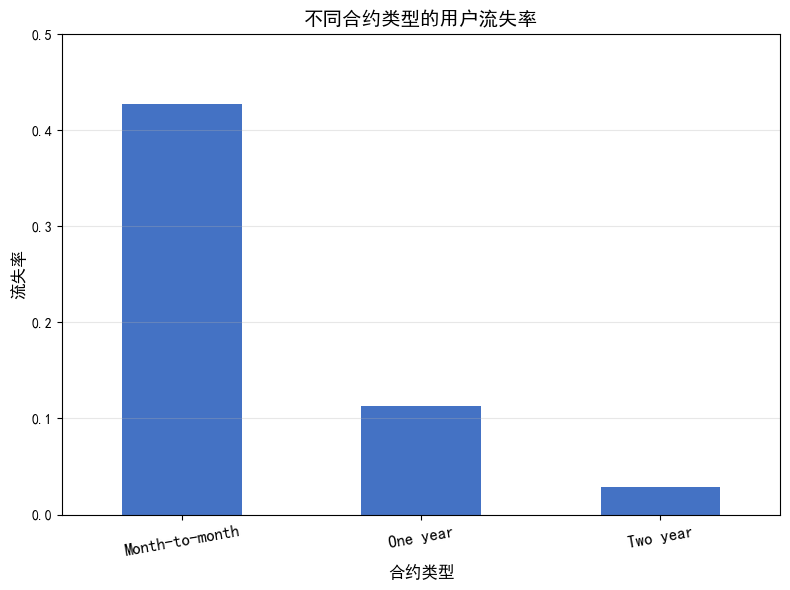

In [42]:
# 2. 不同合约类型、宽带类型、付费方式的流失率可视化
# 2.1 不同合约类型的流失率-按合约分组，计算每组Churn=Yes的占比
contract_churn_rate = df.groupby('Contract')['Churn'].apply(lambda x:(x=='Yes').mean())

print('\n----------各合约类型的流失率----------')
print(contract_churn_rate)

plt.figure(figsize=(8,6))
contract_churn_rate.plot(kind='bar',color='#4472c4')
plt.title('不同合约类型的用户流失率',fontsize=14)
plt.ylabel('流失率',fontsize=12)
plt.xlabel('合约类型',fontsize=12)
plt.xticks(rotation=10,fontsize=12)
plt.ylim(0,0.5)
plt.grid(axis='y',alpha=0.3)
# 自动调整画布内所有元素的位置
plt.tight_layout()
plt.savefig('../output/figures/contract_churn_rate.png',dpi=500,bbox_inches='tight')
plt.show()


----------各宽带类型的流失率----------
InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64


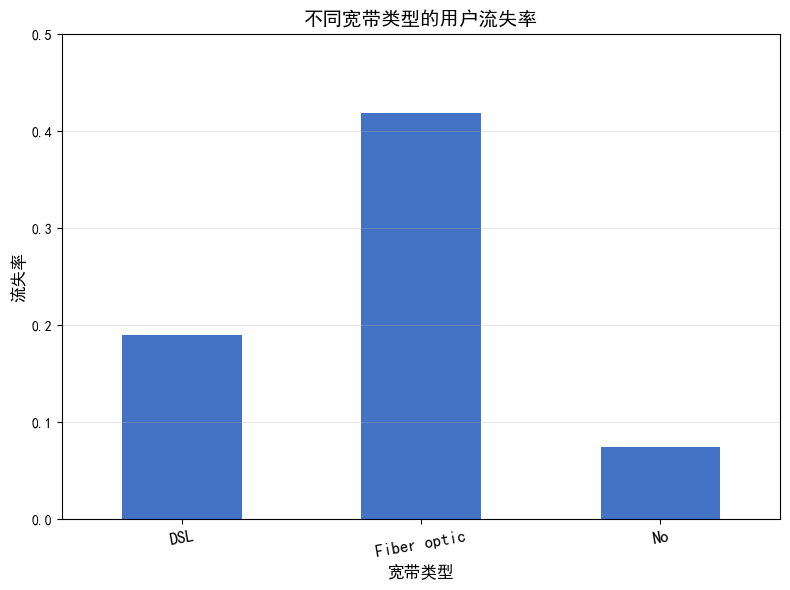

In [43]:
# 2.2 不同宽带类型的流失率-按宽带类型分组，计算每组Churn=Yes的占比
internetService_churn_rate = df.groupby('InternetService')['Churn'].apply(lambda x:(x=='Yes').mean())

print('\n----------各宽带类型的流失率----------')
print(internetService_churn_rate)

plt.figure(figsize=(8,6))
internetService_churn_rate.plot(kind='bar',color='#4472c4')
plt.title('不同宽带类型的用户流失率',fontsize=14)
plt.ylabel('流失率',fontsize=12)
plt.xlabel('宽带类型',fontsize=12)
plt.xticks(rotation=10,fontsize=12)
plt.ylim(0,0.5)
plt.grid(axis='y',alpha=0.3)
# 自动调整画布内所有元素的位置
plt.tight_layout()
plt.savefig('../output/figures/internetService_churn_rate.png',dpi=500,bbox_inches='tight')
plt.show()


----------各宽带类型的流失率----------
PaymentMethod
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Electronic check             0.452854
Mailed check                 0.191067
Name: Churn, dtype: float64


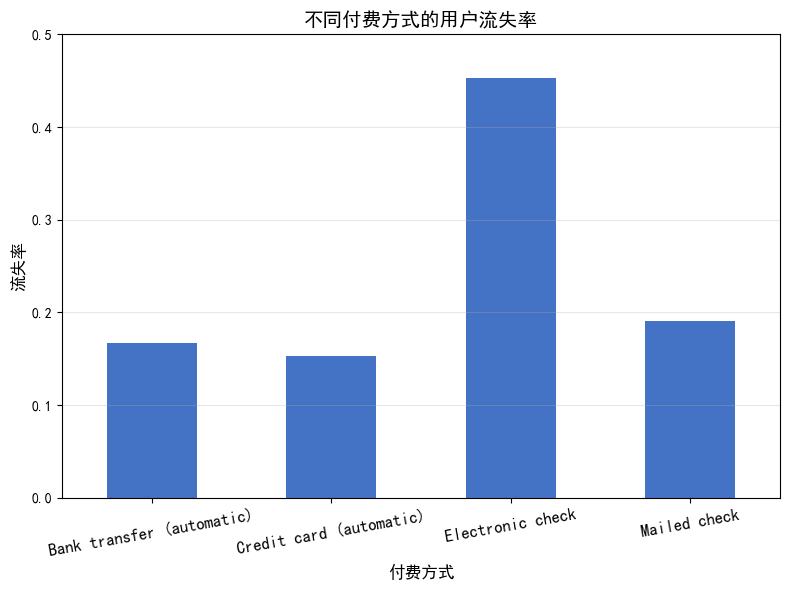

In [44]:
# 2.3 不同付费方式的流失率-按付费分组，计算每组Churn=Yes的占比
paymentMethod_churn_rate = df.groupby('PaymentMethod')['Churn'].apply(lambda x:(x=='Yes').mean())

print('\n----------各宽带类型的流失率----------')
print(paymentMethod_churn_rate)

plt.figure(figsize=(8,6))
paymentMethod_churn_rate.plot(kind='bar',color='#4472c4')
plt.title('不同付费方式的用户流失率',fontsize=14)
plt.ylabel('流失率',fontsize=12)
plt.xlabel('付费方式',fontsize=12)
plt.xticks(rotation=10,fontsize=12)
plt.ylim(0,0.5)
plt.grid(axis='y',alpha=0.3)
# 自动调整画布内所有元素的位置
plt.tight_layout()
plt.savefig('../output/figures/paymentMethod_churn_rate.png',dpi=500,bbox_inches='tight')
plt.show()